# Figure 1d. Local-program power versus TransPCO

Paired power comparison across 72 simulated conditions: homogeneous and heterogeneous effects, three per-SNP trans-heritability levels, three residual-correlation levels, and four causal-gene proportions. Each estimate summarizes 1,000 simulated datasets with 20 program genes and 1,000 donors. Points above the dashed diagonal favor TransMap-local. Color denotes signal-to-noise ratio, shape denotes the causal-gene proportion, and the small interior marks denote residual correlation (none, horizontal, diagonal for 0.1, 0.3, 0.5).

Input: `data/Figure_1d_local_transpco_power.rds` (72 plot-ready summary rows).

In [1]:
suppressPackageStartupMessages(library(ggplot2))
d <- readRDS("data/Figure_1d_local_transpco_power.rds")
stopifnot(nrow(d) == 72L, all(table(d$effect_mode, d$s, d$rho, d$causal_fraction) == 1L),
          all(d$power_transpco >= 0.30 & d$power_transpco <= 1.03),
          all(d$power_transmap_local >= 0.30 & d$power_transmap_local <= 1.03))
d$mark_color <- ifelse(d$s == 0.0025, "#FFFFFF", "#202020")
d$mark_x0 <- d$power_transpco - 0.006
d$mark_x1 <- d$power_transpco + 0.006
d$mark_y0 <- d$power_transmap_local - ifelse(d$rho == 0.5, 0.006, 0)
d$mark_y1 <- d$power_transmap_local + ifelse(d$rho == 0.5, 0.006, 0)

Warning message:
"package 'ggplot2' was built under R version 4.4.3"


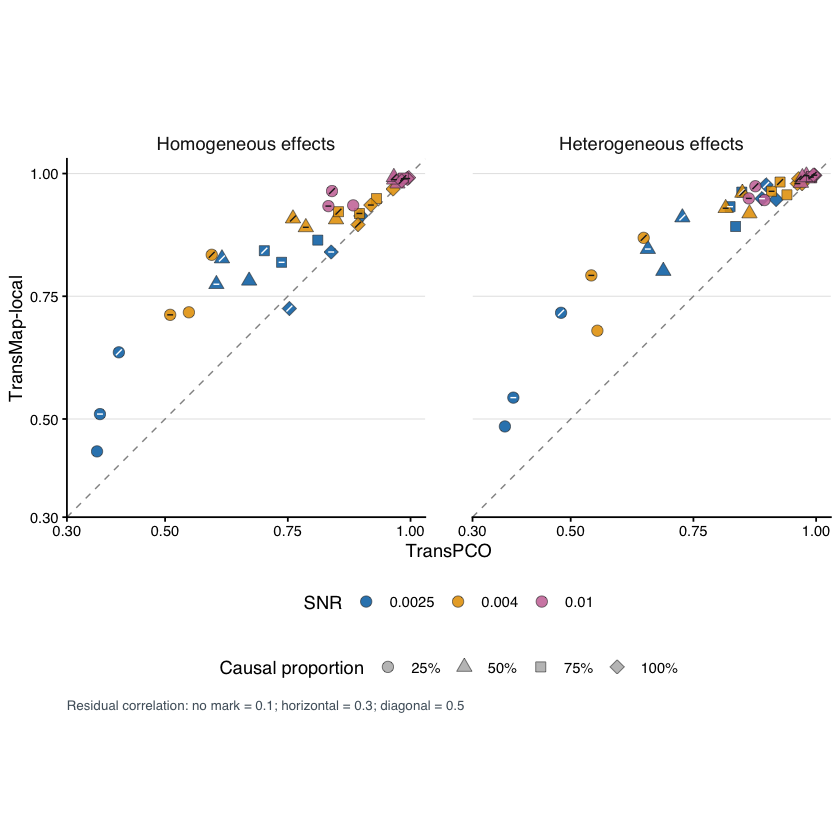

In [2]:
p <- ggplot(d, aes(x = power_transpco, y = power_transmap_local)) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed",
              linewidth = 0.4, color = "#939393") +
  geom_point(aes(fill = snr_label, shape = causal_label),
             size = 3.0, stroke = 0.28, color = "#303030", alpha = 0.88) +
  geom_segment(data = subset(d, rho != 0.1),
               aes(x = mark_x0, xend = mark_x1, y = mark_y0, yend = mark_y1,
                   color = mark_color), inherit.aes = FALSE, linewidth = 0.4) +
  scale_fill_manual(values = c("0.0025" = "#0072B2", "0.004" = "#E69F00",
                               "0.01" = "#CC79A7"), name = "SNR") +
  scale_shape_manual(values = c("25%" = 21, "50%" = 24,
                                "75%" = 22, "100%" = 23), name = "Causal proportion") +
  scale_color_identity(guide = "none") +
  scale_x_continuous(breaks = c(0.3, 0.5, 0.75, 1),
                     labels = c("0.30", "0.50", "0.75", "1.00")) +
  scale_y_continuous(breaks = c(0.3, 0.5, 0.75, 1),
                     labels = c("0.30", "0.50", "0.75", "1.00")) +
  coord_fixed(xlim = c(0.30, 1.03), ylim = c(0.30, 1.03), expand = FALSE) +
  facet_wrap(~effect_mode, nrow = 1,
             labeller = as_labeller(c(homogeneous = "Homogeneous effects",
                                       heterogeneous = "Heterogeneous effects"))) +
  labs(x = "TransPCO", y = "TransMap-local",
       caption = "Residual correlation: no mark = 0.1; horizontal = 0.3; diagonal = 0.5") +
  guides(fill = guide_legend(order = 1, nrow = 1,
                             override.aes = list(shape = 21, size = 3, color = "#303030")),
         shape = guide_legend(order = 2, nrow = 1,
                              override.aes = list(fill = "#B8B8B8"))) +
  theme_classic(base_size = 11, base_family = "sans") +
  theme(panel.grid.major.y = element_line(color = "#E6E6E6", linewidth = 0.3),
        panel.spacing.x = grid::unit(1.0, "cm"),
        strip.background = element_blank(),
        strip.text = element_text(size = 11),
        legend.position = "bottom",
        legend.box = "vertical",
        plot.caption = element_text(hjust = 0, size = 8, color = "#52616C"))
print(p)